# Ex-Post Risk Information

The previous analysis constructed ERC and GMV portfolios using covariance matrices estimated from historical returns.

A natural question is whether the behaviour of these optimized portfolios is driven primarily by the portfolio construction method itself or by our inability to estimate future risk accurately.

To investigate this, this notebook considers an unrealistic but informative setting:

> **What would portfolio construction look like if the covariance structure of the next 36 months were known in advance?**

Only future risk information is assumed to be known. Future expected returns remain unknown.

The purpose is not to construct an implementable strategy, but to **isolate the effect of covariance estimation error**.

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd 
import numpy as np 
import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt
from pathlib import Path
import matplotlib.pyplot as plt

In [5]:
rets = pd.read_csv("../data/processed/rets_81.csv", index_col = 0)
rets_ewcw = pd.read_csv("../data/processed/rets_81_ew_cw.csv", index_col= 0)

In [95]:
rets.head()

,AAPL,ABT,ADI,AEP,AFL,AMAT,AMGN,APD,AXP,BAC,...,SLB,SO,SYY,TJX,TROW,TXN,UNH,UNP,WFC,WMT
MthCalDt,,,,,,,,,,,,,,,,,,,,,
1992-01,0.148559,-0.069056,0.065789,-0.054745,-0.012552,0.088652,-0.069307,0.071066,0.006098,0.076655,...,-0.046092,-0.034848,-0.097125,0.058667,0.033333,0.162602,0.117450,-0.120773,0.129310,-0.084926
1992-02,0.044422,-0.003914,-0.037037,-0.028022,0.020353,0.133550,-0.074468,0.080569,0.018182,0.135336,...,0.013445,-0.045977,0.071429,0.063380,-0.021505,0.048951,-0.039039,0.043956,0.062977,0.002320
1992-03,-0.137037,-0.041257,0.000000,-0.004049,-0.083333,-0.083333,-0.042146,-0.004094,0.101126,0.011494,...,-0.068750,0.024096,0.036111,-0.013245,-0.188544,-0.125290,-0.009375,-0.003406,0.012567,-0.012926
1992-04,0.032189,0.087059,0.064103,0.040650,0.036364,-0.072100,-0.104000,0.106195,-0.016393,0.025568,...,0.111857,0.049099,0.050313,-0.127517,-0.061224,0.061303,-0.034330,0.132979,0.130357,-0.018779
1992-05,-0.006237,0.009470,-0.048193,0.007106,0.017156,0.216216,0.089286,0.005333,0.011111,0.020715,...,0.062985,0.026616,0.028133,0.092411,0.036232,0.086643,0.160131,0.000000,0.014218,0.014354


## Methodology

For each month $t$, two different information sets can be considered.

In the realistic out-of-sample setting, portfolio weights are constructed using the covariance matrix estimated from the **previous 36 months**:

$$
R_{t-36:t-1}
\rightarrow
\hat{\Sigma}^{past}_t
\rightarrow
w_t
$$

In the ex-post setting, the covariance matrix is instead estimated using the **next 36 months of realized returns**:

$$
R_{t:t+35}
\rightarrow
\hat{\Sigma}^{future}_t
\rightarrow
w_t^{oracle}
$$


In [34]:
gmv_weights = {}

for i in range(len(rets)-35):
    date = rets.index[i]

    window = rets.iloc[i:i+36]
    cov = pt.shrinkage_cov(window, delta =0)

    w = pt.gmv_star(cov, max_weight=1)

    gmv_weights[date] = w

In [35]:
gmv_weights = pd.DataFrame(gmv_weights).T

In [38]:
gmv_weights.columns = rets.columns

In [37]:
erc_weights = {}

for i in range(len(rets) - 35):
    date = rets.index[i]

    window = rets.iloc[i:i+36]
    cov = pt.shrinkage_cov(window)

    w = pt.risk_parity_weights(cov)

    erc_weights[date] = w

erc_weights = pd.DataFrame(
    erc_weights,
    index=rets.columns
).T

In [75]:
index = erc_weights.index
rets_gmv = (rets * gmv_weights).sum(axis = 'columns')[index]
rets_erc = (rets * erc_weights).sum(axis = 'columns')[index]

In [76]:
btr = rets_ewcw.loc[index]
btr['GMV'] = rets_gmv
btr['ERC'] = rets_erc

<Axes: title={'center': 'EW vs CW vs GMV & ERC\n Ex-post Covariance'}>

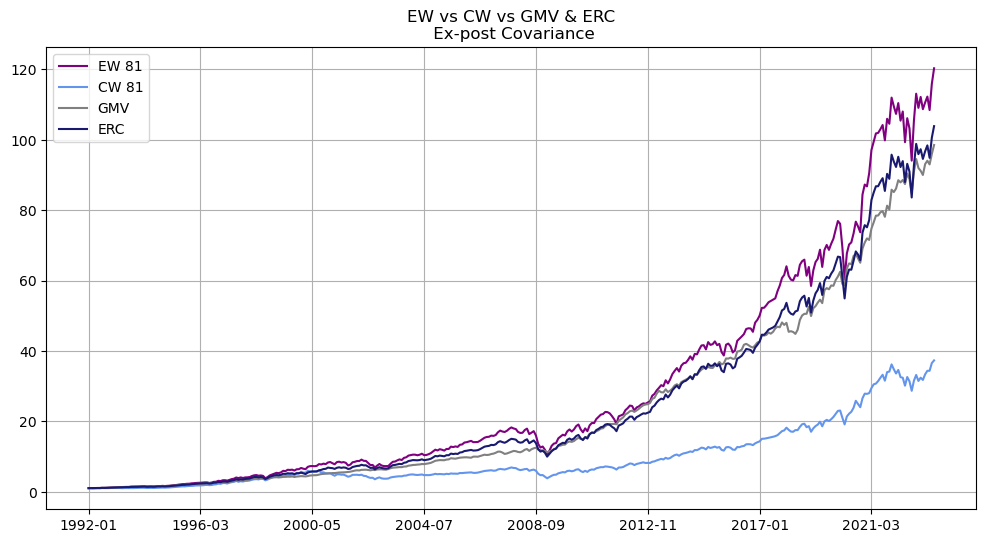

In [96]:
(btr+1).cumprod().plot(figsize = (12,6), grid = True, color = ["purple", "cornflowerblue", "grey", "midnightblue"],
                       title = 'EW vs CW vs GMV & ERC\n Ex-post Covariance')

In [94]:
pt.summary_stats(btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW 81,0.163772,0.147671,-0.450340,4.410603,0.060474,0.091518,0.906993,-0.425269
CW 81,0.121409,0.146029,-0.412285,3.579378,0.063070,0.089173,0.658865,-0.447946
GMV,0.156428,0.072308,-0.095996,3.784320,0.022124,0.034599,1.648561,-0.103112
ERC,0.158370,0.122575,-0.448260,4.165236,0.048713,0.072004,1.026425,-0.336810


## Conclusion

The ex-post experiment shows that the quality of covariance information has a substantial impact on optimized portfolio performance.

In particular, GMV benefits dramatically from knowing the future covariance structure. Its realized volatility falls considerably compared with the realistic out-of-sample implementation, while its risk-adjusted performance improves strongly.

Similarly, ERC benefits from improved risk information, although the effect is less extreme.

This suggests that some of the disappointing behaviour observed for optimized portfolios in 02_100stock.ipynb should not necessarily be attributed to the portfolio objectives themselves. **Covariance estimation error is an important part of the problem.**

At the same time, this experiment represents an oracle benchmark rather than an investable strategy.

CW is simple, transparent, and requires no estimation, but it systematically allocates more capital to larger firms and, in the examined universe, resulted in substantially greater concentration of both capital and risk than equal weighting. Ex-post, CW looks as an absolute looser to alternatives. Yet, the most important finding is that in this universe naive diversification (EW) performed the best, It outperformed the ex-post results of ERC and GMV (not risk-adjusted basis). 